# P12: the training doctor

The brief asks for **training monitoring and failure diagnosis**. P02 to P08 read the learning curves (loss and accuracy):
they tell *that* a network trains badly, rarely *why*. This notebook looks inside the network while it trains, in the
spirit of TP05 and TP06: we make it fail on purpose, one failure at a time, read the symptoms, and check that the cure works.

`fit(..., monitor=True)` (in `utils.py`) records, without changing the training (checked bit for bit):

| measure | what it is | what a healthy value looks like |
|---|---|---|
| `batch_loss` | the loss of every batch | falls, with some noise; never explodes, never NaN |
| `grad_norm` | per layer with weights: mean norm of the gradient of its weights over an epoch | similar order of magnitude across layers |
| `update_ratio` | per layer: norm of (weights after the step - before) / norm of the weights before, mean over an epoch | about 1e-3 (a rule of thumb): 1e-5 barely learns, near 1 rewrites the layer at every step |
| `act_std` | per activation layer: spread of its outputs over the training images | stays of the same order from the first layer to the last |
| `dead` | per activation layer: share of its units that are never positive on any training image | 0: a dead ReLU outputs 0 and its weights get no gradient; it comes back only if the layers below change its inputs |
| `saturated` | per sigmoid / tanh layer: share of outputs stuck at the flat ends | small: there the gradient almost vanishes |

**The patient** is a dense network on the 32 x 32 images of P02 (3,072 numbers per image, standardised with the train
statistics), because one training run takes about a second. The P02 baseline is the healthy reference: one hidden layer of
128 ReLUs, Adam, learning rate 1e-3, batches of 64, 30 epochs, seed 0. Every patient changes **one thing** from a healthy
network. Plain SGD is used where the course uses it: Adam rescales every step by the size of past gradients, which hides some
failures (it keeps every ReLU of the baseline alive even at a learning rate of 1).

Only museum A (train and validation) is used. Nothing is saved in `results/` and museum B is never touched (ADR 0003): these
are diagnoses, not models. Scores are best epochs on 480 validation images (about +/- 4 points), one seed: read them as
"trains" or "does not train", not as a ranking.

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    activation_stats, build_mlp, evaluate, fit, load_data, monitored_layers)

data = load_data(size=32)  # museum A only: train (1,920) and validation (480), standardised, flattened
EPOCHS = 30


def mlp(**config):
    """A dense network on 32 px images (build_mlp), always with the same starting weights (seed 0)."""
    torch.manual_seed(0)
    return build_mlp({"image_size": 32, **config})


def train(model, d=None, epochs=EPOCHS, **settings):
    """fit with the monitoring on, seed 0, silent. settings go to fit (lr, optimizer, clip_grad_norm...)."""
    return fit(model, data if d is None else d, epochs=epochs, seed=0, verbose=False, monitor=True, **settings)


def summary_row(result):
    """The few numbers that tell a healthy run from a sick one."""
    h = result["history"]
    finite = [x for x in h["batch_loss"] if math.isfinite(x)]
    first_layer = next(iter(h["grad_norm"]))
    return {
        "largest batch loss": max(finite) if finite else math.nan,
        "NaN loss": any(math.isnan(x) for x in h["batch_loss"]),
        "train loss, last epoch": h["train_loss"][-1],
        "train acc, last epoch": h["train_acc"][-1],
        "val acc, best epoch": result["best_val_acc"],
        "grad norm, layer 1, epoch 1": h["grad_norm"][first_layer][0],
        "update ratio, layer 1, epoch 1": h["update_ratio"][first_layer][0],
        "dead units, last epoch (worst layer)": max(v[-1] for v in h["dead"].values()),
    }


def table(results):
    return pd.DataFrame([summary_row(r) for r in results.values()], index=list(results))  # one row per run


print("train:", tuple(data["X_train"].shape), "| validation:", tuple(data["X_val"].shape))

train: (1920, 3072) | validation: (480, 3072)


## 1. Sanity checks before any diagnosis

Three checks that cost seconds and catch bugs that no tuning can fix (the data, the labels, the loss or the training loop):

1. **The loss before training.** With random weights and 5 balanced classes the network should guess uniformly: loss near
   ln 5 = 1.61, accuracy near 20%.
2. **Learn one batch by heart.** 64 images, many steps: a working network and training loop must reach 100% on them. If it
   cannot, something is broken, whatever the validation says.
3. **Random labels.** The genres of the training images are shuffled. A network with enough weights can still learn the
   training set by heart, but validation must stay at chance (20%): there is nothing to generalise. It measures how much the
   network can memorise, which is what P02's overfitting was about.

In [2]:
model = mlp(hidden=[128])  # the P02 baseline: same layers, same starting weights
loss0, acc0 = evaluate(model, data["X_train"], data["y_train"])
print(f"before training: loss {loss0:.3f} (ln 5 = {math.log(5):.3f}), accuracy {acc0:.1%} (chance 20%)")

before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4% (chance 20%)


In [3]:
batch = torch.randperm(len(data["X_train"]), generator=torch.Generator().manual_seed(0))[:64]
one_batch = dict(data, X_train=data["X_train"][batch], y_train=data["y_train"][batch])
one = train(mlp(hidden=[128]), one_batch, epochs=100)  # a single batch, so one epoch is one step
h = one["history"]
first_perfect = next(e + 1 for e, acc in enumerate(h["train_acc"]) if acc == 1.0)
print(f"one batch of 64 images: 100% train accuracy first reached after {first_perfect} steps, "
      f"loss after 100 steps {h['train_loss'][-1]:.4f}; validation {h['val_acc'][-1]:.1%} (it learnt 64 images, nothing more)")

one batch of 64 images: 100% train accuracy first reached after 7 steps, loss after 100 steps 0.0003; validation 27.7% (it learnt 64 images, nothing more)


after shuffling, 19.6% of the training labels are still right (chance: 20%)


                           train acc, last epoch  val acc, best epoch  \
true labels, 200 epochs                      1.0                0.392   
random labels, 200 epochs                    1.0                0.233   

                           train loss, last epoch  
true labels, 200 epochs                       0.0  
random labels, 200 epochs                     0.0  
random labels, validation over the last 50 epochs: mean 19.0%


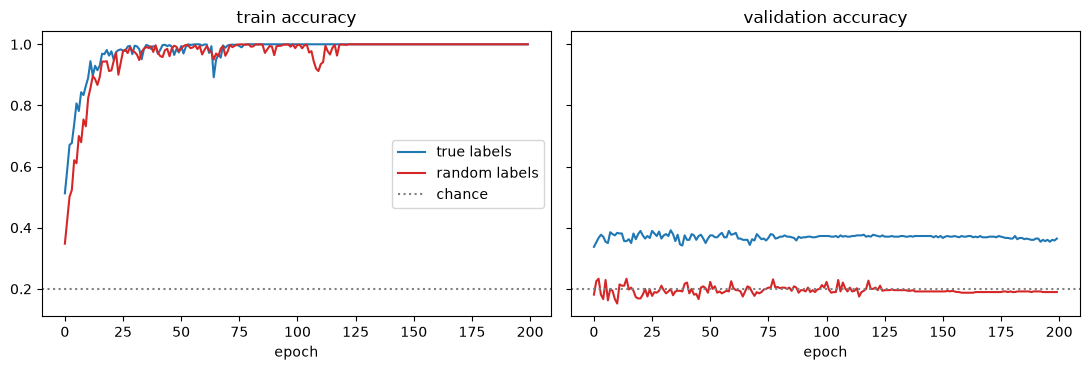

In [4]:
shuffled = torch.randperm(len(data["y_train"]), generator=torch.Generator().manual_seed(1))
random_labels = dict(data, y_train=data["y_train"][shuffled])
agreement = (random_labels["y_train"] == data["y_train"]).float().mean().item()
print(f"after shuffling, {agreement:.1%} of the training labels are still right (chance: 20%)")

true_run = train(mlp(hidden=[128]), epochs=200)
random_run = train(mlp(hidden=[128]), random_labels, epochs=200)
print(table({"true labels, 200 epochs": true_run, "random labels, 200 epochs": random_run})
      [["train acc, last epoch", "val acc, best epoch", "train loss, last epoch"]].round(3))
print(f"random labels, validation over the last 50 epochs: mean {pd.Series(random_run['history']['val_acc'][-50:]).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, split in zip(axes, ["train_acc", "val_acc"]):
    ax.plot(true_run["history"][split], label="true labels", color="tab:blue")
    ax.plot(random_run["history"][split], label="random labels", color="tab:red")
    ax.axhline(0.2, color="grey", linestyle=":", label="chance")
    ax.set_title("train accuracy" if split == "train_acc" else "validation accuracy")
    ax.set_xlabel("epoch")
axes[0].legend()
plt.tight_layout()
plt.show()

**What we see.**

- **The start is right:** loss 1.639 against ln 5 = 1.609, accuracy 16.4%: the untrained network guesses, as in P02.
- **The training loop works:** one batch of 64 images is learnt by heart after 7 steps (loss 0.0003 after 100 steps). Validation stays at 27.7%: 64 images teach nothing general.
- **The network can memorise anything.** With shuffled labels (19.6% of them still right by chance) it still reaches 100% train accuracy, while validation stays at chance (19.0% on average over the last 50 epochs; 23.3% at its best epoch, a lucky peak). With the true labels it also reaches 100% train, and 39.2% validation.
- So for this network a high train accuracy proves nothing: its 394k weights can store 1,920 images whatever their labels. P02's 98% train against 39% validation is memorisation, not a training bug. The cure is fewer free weights or regularisation (next notebook), not more or better training.